# Entrega final · Machine Learning I
## Prevalencia y predictores de diabetes en adultos
**Jean Paul Rojas Rojas y Mariana Uribe Vanegas** · Universidad Externado de Colombia · 2026

**Objetivo:** comparar clasificadores supervisados de diabetes y describir factores asociados, sobre el conjunto suministrado de 8.475 adultos.

**Guía de lectura:** ejecuta las celdas de arriba hacia abajo. **Todos los resultados, tablas y figuras aparecen aquí**. El único archivo que se guarda automáticamente es `modelos/modelo_diabetes.joblib`, necesario para la aplicación Streamlit.

## 1. Preparación reproducible

Usamos **Pipeline** para que la imputación, el escalado y la codificación se ajusten dentro de cada partición de entrenamiento. Los identificadores se usan exclusivamente para separación por hogar, **no como predictores**.

In [1]:
from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             precision_score, recall_score, f1_score, roc_curve, precision_recall_curve, make_scorer)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': .18})
BASE = Path.cwd()
# Permite abrir VS Code en el repositorio padre o en la carpeta que contiene el notebook.
if not (BASE / 'datos' / 'base_diabetes_ensanut2025.csv').exists():
    BASE = BASE / 'Prevalencia_Diabetes_ML1_Actualizado' if (BASE / 'Prevalencia_Diabetes_ML1_Actualizado' / 'datos' / 'base_diabetes_ensanut2025.csv').exists() else BASE / 'Proyecto_Machine_Learning'
DATOS = BASE / 'datos' / 'base_diabetes_ensanut2025.csv'
if not DATOS.is_file():
    raise FileNotFoundError(f'No se encontró {DATOS}. Abre la carpeta del proyecto en VS Code y ejecuta de nuevo.')
MODELOS = BASE / 'modelos'
MODELOS.mkdir(exist_ok=True)
NUM = ['EDAD', 'IMC', 'PAS_MEDIA', 'PAD_MEDIA']
CAT = ['SEXO', 'TABAQUISMO', 'CONSUMO_ALCOHOL', 'NIVEL_EDUCATIVO', 'ESTRATO_URBANO']
BIN = ['HIPERTENSION', 'COLESTEROL_ALTO', 'TRIGLICERIDOS_ALTOS', 'ENF_RENAL',
       'ENF_CARDIOVASCULAR', 'DIF_CAMINAR', 'SIN_SEGURO_SALUD', 'TRABAJA']
FEATURES = NUM + CAT + BIN

def construir_pipeline(estimador):
    transformaciones = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                          ('escalar', StandardScaler())]), NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), CAT),
        ('bin', 'passthrough', BIN)
    ])
    return Pipeline([('preprocesamiento', transformaciones), ('modelo', estimador)])

def evaluar(y_real, prob, umbral):
    pred = (np.asarray(prob) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {'Umbral': float(umbral), 'ROC-AUC': float(roc_auc_score(y_real, prob)),
            'PR-AUC': float(average_precision_score(y_real, prob)),
            'Sensibilidad': float(recall_score(y_real, pred, zero_division=0)),
            'Especificidad': float(tn / (tn + fp)),
            'Precisión': float(precision_score(y_real, pred, zero_division=0)),
            'F1': float(f1_score(y_real, pred, zero_division=0)),
            'Exactitud': float((tp + tn) / (tp + tn + fp + fn)),
            'VP': int(tp), 'VN': int(tn), 'FP': int(fp), 'FN': int(fn)}

def umbral_youden(y_real, prob):
    fpr, tpr, umbrales = roc_curve(y_real, prob)
    validos = np.isfinite(umbrales)
    return float(umbrales[validos][np.argmax((tpr - fpr)[validos])])

def ic_bootstrap(y_real, prob, umbral, repeticiones=500):
    # Remuestreo por hogar de prueba para mantener la estructura de agrupación.
    y_arr, p_arr = np.asarray(y_real), np.asarray(prob)
    hogares = np.asarray(gte)
    unicos = pd.unique(hogares)
    indices_hogar = {h: np.flatnonzero(hogares == h) for h in unicos}
    rng = np.random.default_rng(SEED)
    resultados = []
    for _ in range(repeticiones):
        seleccion = rng.choice(unicos, size=len(unicos), replace=True)
        idx = np.concatenate([indices_hogar[h] for h in seleccion])
        if np.unique(y_arr[idx]).size < 2:
            continue
        valores = evaluar(y_arr[idx], p_arr[idx], umbral)
        resultados.append([valores[k] for k in ['Sensibilidad', 'Precisión', 'ROC-AUC', 'PR-AUC']])
    matriz = np.asarray(resultados)
    return pd.DataFrame({'Métrica': ['Sensibilidad', 'Precisión', 'ROC-AUC', 'PR-AUC'],
                         'Límite inferior (95%)': np.quantile(matriz, .025, axis=0),
                         'Límite superior (95%)': np.quantile(matriz, .975, axis=0)})

def tabla_estilo(tabla, formatos=None, degradado=None, resaltar=None):
    s = tabla.style.hide(axis='index').format(formatos or {}, na_rep='—')
    if degradado:
        s = s.background_gradient(cmap='YlGn', subset=degradado)
    if resaltar:
        s = s.highlight_max(subset=resaltar, color='#a8d5a2')
    return s.set_table_styles([
        {'selector': 'th.col_heading', 'props': [('background-color', '#185d46'), ('color', 'white'), ('padding', '9px')]},
        {'selector': 'td', 'props': [('padding', '7px'), ('border-bottom', '1px solid #ddd')]}
    ])

display(Markdown('**Bibliotecas cargadas y funciones definidas correctamente.**'))

**Bibliotecas cargadas y funciones definidas correctamente.**

## 2. Lectura de datos y auditoría descriptiva

Identificamos la prevalencia de la clase positiva, los datos faltantes y las características de cada grupo. No alteramos los valores atípicos sin evidencia de error.

In [2]:
df = pd.read_csv(DATOS)
assert len(df) == 8475, 'La base no coincide con los 8.475 registros documentados.'
assert df['FOLIO_INT'].is_unique, 'Existen identificadores individuales repetidos.'
assert set(df['DIABETES'].unique()) == {0, 1}, 'La variable objetivo debe ser binaria 0/1.'
assert set(FEATURES).issubset(df.columns), 'Faltan predictores en el CSV.'
X = df[FEATURES].copy()
y = df['DIABETES'].astype(int)
groups = df['FOLIO_I'].astype(str)
resumen = pd.DataFrame([
    ['Personas', len(df)], ['Hogares', groups.nunique()],
    ['Sin diabetes', int((y == 0).sum())], ['Con diabetes', int((y == 1).sum())],
    ['Prevalencia (%)', 100 * y.mean()],
    ['Registros completos (%)', 100 * df[FEATURES].notna().all(axis=1).mean()]
], columns=['Indicador', 'Valor'])
display(tabla_estilo(resumen, {'Valor': '{:,.2f}'}))
faltantes = X.isna().sum().loc[lambda s: s > 0].rename_axis('Variable').reset_index(name='Faltantes')
faltantes['Porcentaje'] = faltantes['Faltantes'] / len(df)
display(Markdown('**Variables con valores faltantes**'))
display(tabla_estilo(faltantes, {'Porcentaje': '{:.2%}'}))
descriptivos = df.groupby('DIABETES')[NUM].mean().T
Descriptivos = descriptivos.rename(columns={0: 'Sin diabetes', 1: 'Con diabetes'}).reset_index(names='Variable')
display(Markdown('**Medias de variables numéricas por clase**'))
display(tabla_estilo(Descriptivos, {'Sin diabetes': '{:.2f}', 'Con diabetes': '{:.2f}'}))

Indicador,Valor
Personas,"8,475.00"
Hogares,"6,870.00"
Sin diabetes,"7,067.00"
Con diabetes,"1,408.00"
Prevalencia (%),16.61
Registros completos (%),94.02


**Variables con valores faltantes**

Variable,Faltantes,Porcentaje
IMC,237,2.80%
PAS_MEDIA,283,3.34%
PAD_MEDIA,283,3.34%


**Medias de variables numéricas por clase**

Variable,Sin diabetes,Con diabetes
EDAD,47.84,61.91
IMC,29.64,30.08
PAS_MEDIA,126.27,134.99
PAD_MEDIA,75.29,74.44


## 3. Partición agrupada y validación cruzada

Separamos aproximadamente el 20% para prueba mediante `StratifiedGroupKFold`. Ningún hogar aparece en ambos subconjuntos. Se mantiene la semilla 42 y el preprocesamiento ocurre dentro de cada pliegue.

> **Limitación:** la segunda entrega ya había usado individuos de esta base para evaluar modelos. El nuevo holdout por hogares reduce la fuga intrahogar, pero el análisis de esta misma fuente no puede calificarse de validación externa independiente.

In [3]:
split_holdout = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_train, idx_test = next(split_holdout.split(X, y, groups))
xtr, xte = X.iloc[idx_train], X.iloc[idx_test]
ytr, yte = y.iloc[idx_train], y.iloc[idx_test]
gtr, gte = groups.iloc[idx_train], groups.iloc[idx_test]
assert set(gtr).isdisjoint(set(gte)), 'Se encontraron hogares compartidos.'
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
particion = pd.DataFrame([
    ['Entrenamiento', len(xtr), gtr.nunique(), ytr.mean()],
    ['Prueba', len(xte), gte.nunique(), yte.mean()]
], columns=['Conjunto', 'Personas', 'Hogares', 'Prevalencia'])
display(tabla_estilo(particion, {'Prevalencia': '{:.2%}'}))
display(Markdown('**Verificación:** 0 hogares compartidos entre entrenamiento y prueba.'))

Conjunto,Personas,Hogares,Prevalencia
Entrenamiento,6780,5489,16.62%
Prueba,1695,1381,16.58%


**Verificación:** 0 hogares compartidos entre entrenamiento y prueba.

## 4. Entrenamiento y comparación de modelos

Se comparan modelos vistos en el curso con la línea base de mayoría. Los hiperparámetros se eligen por ROC-AUC exclusivamente en entrenamiento. La tabla muestra métricas **a umbral 0,50** obtenidas mediante validación cruzada agrupada.

**Matiz metodológico:** la validación posterior usa los parámetros elegidos sobre los mismos datos, por lo que puede tener cierto optimismo (no es validación anidada). No utilizamos la prueba para elegir parámetros ni el umbral.

In [4]:
modelos = {
    'Mayoría': (DummyClassifier(strategy='most_frequent'), {}),
    'Logística L2': (LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED),
                     {'modelo__C': [.01, .1, 1, 10]}),
    'QDA': (QuadraticDiscriminantAnalysis(), {'modelo__reg_param': [.1, .3, .5, .7, .9]}),
    'Naive Bayes': (GaussianNB(), {'modelo__var_smoothing': [.001, .01, .1, .3, .5, 1.]}),
    'KNN': (KNeighborsClassifier(), {'modelo__n_neighbors': [21, 41, 61, 81, 101],
                                     'modelo__weights': ['uniform', 'distance'],
                                     'modelo__metric': ['manhattan', 'euclidean']})
}
filas, mejores = [], {}
for nombre, (estimador, grid) in modelos.items():
    pipe_candidato = construir_pipeline(estimador)
    if grid:
        busqueda = GridSearchCV(pipe_candidato, grid, scoring='roc_auc', cv=cv,
                                n_jobs=1, refit=True, error_score='raise')
        busqueda.fit(xtr, ytr, groups=gtr)
        pipe_candidato, parametros = busqueda.best_estimator_, busqueda.best_params_
    else:
        parametros = {}
    medidas = cross_validate(pipe_candidato, xtr, ytr, groups=gtr, cv=cv,
                             scoring={'auc': 'roc_auc', 'recall': 'recall',
                                      'precision': make_scorer(precision_score, zero_division=0), 'f1': 'f1'}, n_jobs=1)
    filas.append({'Modelo': nombre,
                  'Hiperparámetros': ', '.join(f'{k.replace("modelo__", "")}={v}' for k, v in parametros.items()) or '—',
                  'ROC-AUC': medidas['test_auc'].mean(), 'DE ROC-AUC': medidas['test_auc'].std(),
                  'Sensibilidad': medidas['test_recall'].mean(),
                  'DE sensibilidad': medidas['test_recall'].std(),
                  'Precisión': medidas['test_precision'].mean(), 'F1': medidas['test_f1'].mean()})
    mejores[nombre] = pipe_candidato
comparacion = pd.DataFrame(filas).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
display(Markdown('### Resultados de validación cruzada · 5 pliegues por hogar'))
display(tabla_estilo(comparacion,
    {'ROC-AUC': '{:.4f}', 'DE ROC-AUC': '{:.4f}', 'Sensibilidad': '{:.1%}',
     'DE sensibilidad': '{:.1%}', 'Precisión': '{:.1%}', 'F1': '{:.4f}'},
    degradado=['ROC-AUC', 'Sensibilidad'], resaltar=['ROC-AUC', 'Sensibilidad']))
display(Markdown(f"**Mayor ROC-AUC:** {comparacion.iloc[0]['Modelo']} ({comparacion.iloc[0]['ROC-AUC']:.4f}). "
                 "El mejor ROC-AUC no determina por sí solo cuál modelo conviene para tamizaje."))

### Resultados de validación cruzada · 5 pliegues por hogar

Modelo,Hiperparámetros,ROC-AUC,DE ROC-AUC,Sensibilidad,DE sensibilidad,Precisión,F1
KNN,"metric=manhattan, n_neighbors=81, weights=distance",0.8022,0.0221,4.7%,0.8%,62.8%,0.0871
QDA,reg_param=0.1,0.8013,0.0214,35.0%,3.2%,45.6%,0.3951
Naive Bayes,var_smoothing=0.1,0.7958,0.0179,46.5%,1.1%,40.7%,0.4337
Logística L2,C=0.1,0.7932,0.0164,72.6%,1.9%,33.4%,0.4576
Mayoría,—,0.5000,0.0000,0.0%,0.0%,0.0%,0.0000


**Mayor ROC-AUC:** KNN (0.8022). El mejor ROC-AUC no determina por sí solo cuál modelo conviene para tamizaje.

## 5. Modelo principal, umbral y evaluación de prueba

Se conserva **regresión logística L2** por su interpretabilidad y sensibilidad; se fija el umbral con predicciones fuera de pliegue de entrenamiento y el índice de Youden. Después se ajusta con todo el entrenamiento y se evalúa en la prueba separada por hogares.

Se muestra tanto el umbral 0,50 como el umbral elegido, para hacer explícito el intercambio entre falsos positivos y negativos.

In [5]:
pipe = mejores['Logística L2']
probs_oof = cross_val_predict(pipe, xtr, ytr, groups=gtr, cv=cv,
                              method='predict_proba', n_jobs=1)[:, 1]
t = umbral_youden(ytr, probs_oof)
pipe.fit(xtr, ytr)
probs = pipe.predict_proba(xte)[:, 1]
pred = (probs >= t).astype(int)
metricas_050 = evaluar(yte, probs, .5)
metricas_final = evaluar(yte, probs, t)
metricas_tabla = pd.DataFrame([metricas_050, metricas_final],
                             index=['Umbral 0,50', 'Umbral Youden (entrenamiento)']).reset_index(names='Configuración')
display(Markdown(f'**Umbral elegido sin consultar la prueba: `{t:.4f}`.**'))
display(tabla_estilo(metricas_tabla, {k: '{:.3f}' for k in
    ['Umbral','ROC-AUC','PR-AUC','Sensibilidad','Especificidad','Precisión','F1','Exactitud']},
    degradado=['Sensibilidad','Especificidad']))
intervalos = ic_bootstrap(yte, probs, t)
display(Markdown('### Incertidumbre de las métricas · bootstrap agrupado por hogar (500 remuestreos)'))
display(tabla_estilo(intervalos, {'Límite inferior (95%)': '{:.3f}', 'Límite superior (95%)': '{:.3f}'}))
display(Markdown(f"**Lectura:** se identificaron {metricas_final['VP']} de {int(yte.sum())} positivos, "
                 f"con {metricas_final['FN']} falsos negativos y {metricas_final['FP']} falsos positivos. "
                 "Una clasificación positiva requiere confirmación clínica; el modelo no diagnostica."))

# ÚNICA EXPORTACIÓN: artefacto que consume app.py, sin archivos CSV, Excel, JSON ni figuras.
artefacto = {'pipeline': pipe, 'umbral': t, 'features': FEATURES,
            'categorias': {c: sorted(df[c].dropna().unique().tolist()) for c in CAT},
            'version': 'Fase 3 — separación por hogares'}
joblib.dump(artefacto, MODELOS / 'modelo_diabetes.joblib')
display(Markdown('**Modelo para Streamlit guardado:** `modelos/modelo_diabetes.joblib`'))

**Umbral elegido sin consultar la prueba: `0.3748`.**

Configuración,Umbral,ROC-AUC,PR-AUC,Sensibilidad,Especificidad,Precisión,F1,Exactitud,VP,VN,FP,FN
"Umbral 0,50",0.500,0.767,0.347,0.676,0.714,0.319,0.434,0.707,190,1009,405,91
Umbral Youden (entrenamiento),0.375,0.767,0.347,0.833,0.591,0.288,0.428,0.631,234,836,578,47


### Incertidumbre de las métricas · bootstrap agrupado por hogar (500 remuestreos)

Métrica,Límite inferior (95%),Límite superior (95%)
Sensibilidad,0.783,0.874
Precisión,0.254,0.321
ROC-AUC,0.742,0.794
PR-AUC,0.303,0.406


**Lectura:** se identificaron 234 de 281 positivos, con 47 falsos negativos y 578 falsos positivos. Una clasificación positiva requiere confirmación clínica; el modelo no diagnostica.

**Modelo para Streamlit guardado:** `modelos/modelo_diabetes.joblib`

## 6. Factores asociados: odds ratios

Las razones de momios se obtienen de la regresión logística **ponderada y penalizada**. Para variables numéricas equivalen al incremento de **una desviación estándar** (tras escalado), para binarias a 0→1, y para categorías a la comparación con la categoría de referencia de la codificación one-hot.

**Estas asociaciones no son relaciones causales ni incluyen intervalos de confianza inferenciales.**

Variable codificada,Coeficiente,Odds ratio
bin__TRIGLICERIDOS_ALTOS,+0.658,1.931
num__EDAD,+0.649,1.914
bin__HIPERTENSION,+0.613,1.846
bin__COLESTEROL_ALTO,+0.439,1.551
cat__ESTRATO_URBANO_Urbano,+0.324,1.382
cat__CONSUMO_ALCOHOL_No_consume,+0.264,1.302
cat__NIVEL_EDUCATIVO_Primaria_o_menos,+0.263,1.301
bin__DIF_CAMINAR,+0.259,1.296
bin__ENF_CARDIOVASCULAR,+0.188,1.207
cat__CONSUMO_ALCOHOL_Ocasional,+0.186,1.205


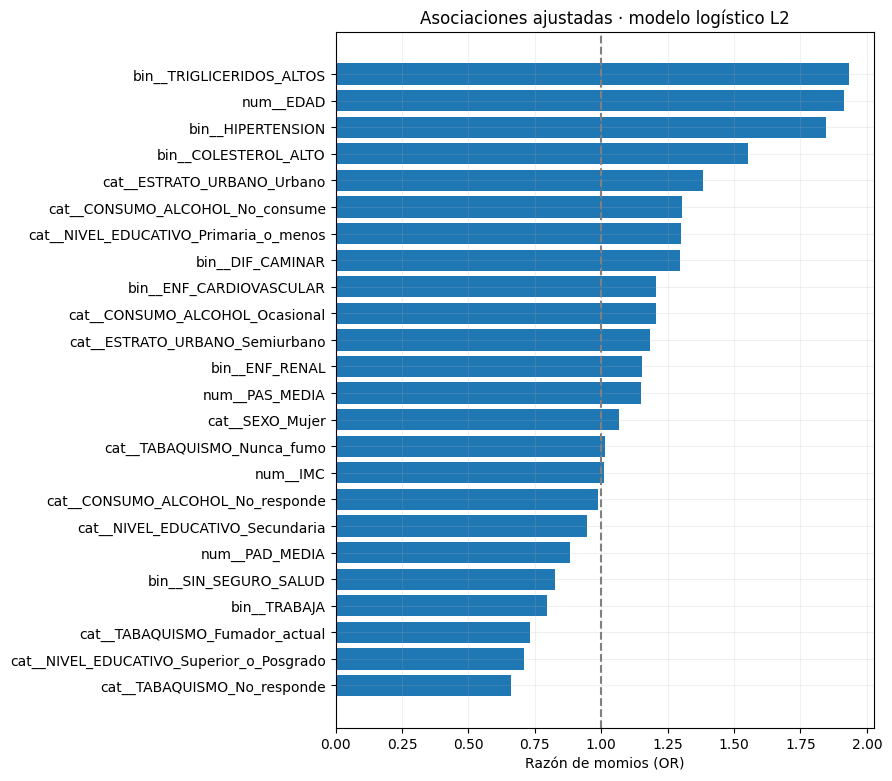

In [6]:
nombres = pipe.named_steps['preprocesamiento'].get_feature_names_out()
coefs = pipe.named_steps['modelo'].coef_[0]
ors = (pd.DataFrame({'Variable codificada': nombres, 'Coeficiente': coefs,
                     'Odds ratio': np.exp(coefs)})
       .sort_values('Odds ratio', ascending=False).reset_index(drop=True))
display(tabla_estilo(ors, {'Coeficiente': '{:+.3f}', 'Odds ratio': '{:.3f}'},
                    degradado=['Odds ratio']))
fig, ax = plt.subplots(figsize=(9, max(4, .33 * len(ors))))
orden = ors.sort_values('Odds ratio')
ax.barh(orden['Variable codificada'], orden['Odds ratio'])
ax.axvline(1, linestyle='--', color='gray')
ax.set_xlabel('Razón de momios (OR)')
ax.set_title('Asociaciones ajustadas · modelo logístico L2')
plt.tight_layout()
plt.show()

## 7. Perfil de errores y sensibilidad por subgrupos

Los falsos negativos son el error prioritario por las posibles consecuencias de no identificar a alguien con diabetes. También mostramos falsos positivos y heterogeneidad descriptiva; en subgrupos pequeños los porcentajes pueden ser inestables.

In [7]:
errores = xte.copy()
errores['Observado'] = yte.to_numpy()
errores['Probabilidad'] = probs
errores['Predicción'] = pred
errores['Tipo'] = np.select([
    (errores['Observado'] == 1) & (errores['Predicción'] == 0),
    (errores['Observado'] == 0) & (errores['Predicción'] == 1),
    (errores['Observado'] == 1) & (errores['Predicción'] == 1)
], ['FN', 'FP', 'VP'], default='VN')
perfil = errores.groupby('Tipo').agg(
    Personas=('Observado', 'size'), Edad_media=('EDAD', 'mean'),
    IMC_medio=('IMC', 'mean'), Hipertensión=('HIPERTENSION', 'mean'),
    Puntuación_media=('Probabilidad', 'mean')
).reset_index()
display(Markdown('### Perfil de los aciertos y errores'))
display(tabla_estilo(perfil, {'Edad_media': '{:.1f}', 'IMC_medio': '{:.1f}',
                              'Hipertensión': '{:.1%}', 'Puntuación_media': '{:.2%}'}))
subgrupos = []
for variable in ['SEXO', 'ESTRATO_URBANO', 'HIPERTENSION']:
    for valor, bloque in errores.groupby(variable, dropna=False):
        positivos = bloque.loc[bloque['Observado'] == 1]
        subgrupos.append({'Variable': variable, 'Grupo': str(valor),
                          'Personas': len(bloque), 'Casos positivos': len(positivos),
                          'Sensibilidad': float((positivos['Predicción'] == 1).mean()) if len(positivos) else np.nan,
                          'FN': int((positivos['Predicción'] == 0).sum())})
tabla_subgrupos = pd.DataFrame(subgrupos)
display(Markdown('### Sensibilidad por subgrupos (descriptiva)'))
display(tabla_estilo(tabla_subgrupos, {'Sensibilidad': '{:.1%}'},
                    degradado=['Sensibilidad']))

### Perfil de los aciertos y errores

Tipo,Personas,Edad_media,IMC_medio,Hipertensión,Puntuación_media
FN,47,47.4,31.2,2.1%,27.34%
FP,578,63.2,29.7,41.7%,61.44%
VN,836,37.1,29.6,3.8%,20.16%
VP,234,64.4,30.0,55.6%,66.44%


### Sensibilidad por subgrupos (descriptiva)

Variable,Grupo,Personas,Casos positivos,Sensibilidad,FN
SEXO,Hombre,652,106,80.2%,21
SEXO,Mujer,1043,175,85.1%,26
ESTRATO_URBANO,Rural,446,65,80.0%,13
ESTRATO_URBANO,Semiurbano,530,93,88.2%,11
ESTRATO_URBANO,Urbano,719,123,81.3%,23
HIPERTENSION,0,1291,150,69.3%,46
HIPERTENSION,1,404,131,99.2%,1


## 8. Figuras de evaluación final

La ROC describe la discriminación general, mientras que la curva precisión–sensibilidad es útil con clases desbalanceadas. La matriz de confusión permite observar el costo concreto del umbral fijado antes de usar la prueba.

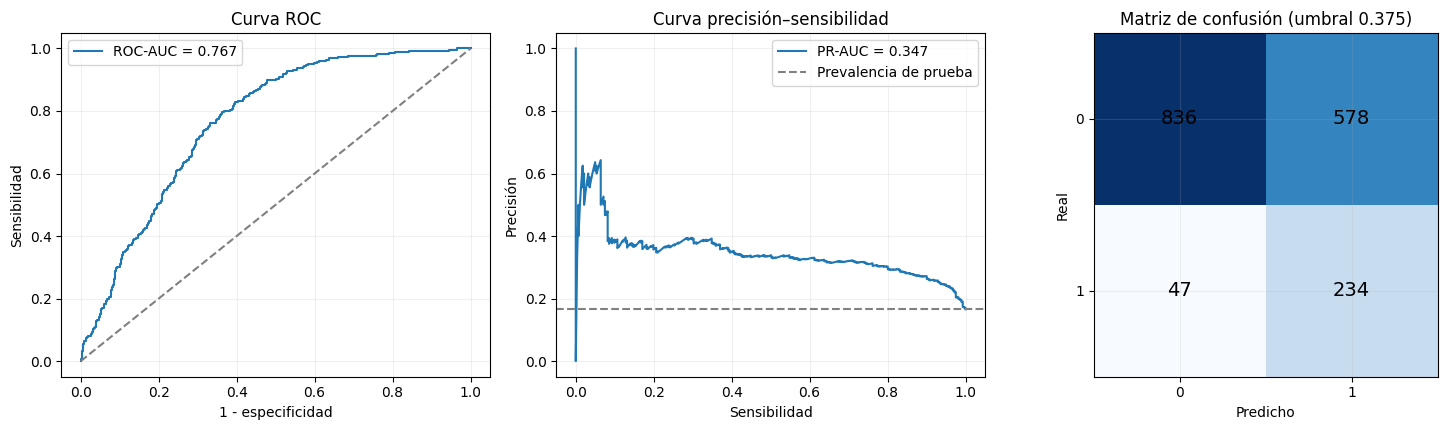

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
fpr, tpr, _ = roc_curve(yte, probs)
axs[0].plot(fpr, tpr, label=f"ROC-AUC = {metricas_final['ROC-AUC']:.3f}")
axs[0].plot([0, 1], [0, 1], linestyle='--', color='gray')
axs[0].set(xlabel='1 - especificidad', ylabel='Sensibilidad', title='Curva ROC')
axs[0].legend()
precisiones, recalls, _ = precision_recall_curve(yte, probs)
axs[1].plot(recalls, precisiones, label=f"PR-AUC = {metricas_final['PR-AUC']:.3f}")
axs[1].axhline(yte.mean(), linestyle='--', color='gray', label='Prevalencia de prueba')
axs[1].set(xlabel='Sensibilidad', ylabel='Precisión', title='Curva precisión–sensibilidad')
axs[1].legend()
matriz = confusion_matrix(yte, pred, labels=[0, 1])
axs[2].imshow(matriz, cmap='Blues')
for (i, j), valor in np.ndenumerate(matriz):
    axs[2].text(j, i, f'{valor}', ha='center', va='center', fontsize=14)
axs[2].set(xticks=[0, 1], yticks=[0, 1], xlabel='Predicho', ylabel='Real',
           title=f'Matriz de confusión (umbral {t:.3f})')
plt.tight_layout()
plt.show()

## 9. Conclusiones y despliegue

- **Modelo principal:** regresión logística L2 con ponderación de clases, por equilibrio entre sensibilidad e interpretabilidad. El mayor ROC-AUC de otra familia no demuestra superioridad por sí mismo.
- **Trade-off:** reducir falsos negativos mediante el umbral elegido incrementa la cantidad de falsos positivos; se necesita confirmación clínica.
- **Validación:** se evitaron hogares compartidos, pero los datos de esta fuente ya se habían utilizado en la fase previa; por eso la evaluación es interna, no validación independiente.
- **Supuestos:** QDA y Naive Bayes gaussianos reciben columnas binarias y one-hot, lo que limita la interpretación de sus hipótesis distributivas.
- **Fuente:** antes de entregar el informe debe verificarse oficialmente la procedencia del CSV de «ENSANUT 2025» y documentarse su país, institución, enlace y condiciones de uso.

### Cómo ejecutar Streamlit

En una terminal abierta **dentro de esta carpeta**, ejecutar:

```bash
python -m pip install -r requirements.txt
streamlit run app.py
```

El archivo `app.py` usa el modelo exportado por el notebook en `modelos/modelo_diabetes.joblib`.

**Declaración de apoyo:** se utilizó una herramienta de IA para ayudar a organizar y depurar el código. El equipo debe verificar, comprender y sustentar todas las decisiones técnicas.